# Building Multi-AI Agent for **Aviation Industry: Transportation, Logistics and Retail**
Author: Dr. Maryam Miradi

# Set Up

## Install Libraries

In [ ]:
!pip install python-dotenv

In [ ]:
!uv pip install --upgrade --system pip

Using Python 3.10.12 environment at /usr
Resolved 1 package in 142ms
⠙ Preparing packages... (0/1)
⠙ Preparing packages... (0/1)
⠙ Preparing packages... (0/1)
⠙ Preparing packages... (0/1)
⠙ Preparing packages... (0/1)
⠙ Preparing packages... (0/1)
⠙ Preparing packages... (0/1)
⠙ Preparing packages... (0/1)
⠙ Preparing packages... (0/1)
⠙ Preparing packages... (0/1)
⠙ Preparing packages... (0/1)
⠙ Preparing packages... (0/1)
⠙ Preparing packages... (0/1)
⠙ Preparing packages... (0/1)
⠙ Preparing packages... (0/1)
⠙ Preparing packages... (0/1)
⠙ Preparing packages... (0/1)
⠙ Preparing packages... (0/1)
⠙ Preparing packages... (0/1)
Prepared 1 package in 151ms
Uninstalled 1 package in 42ms
Installed 1 package in 14ms
 - pip==24.1.2
 + pip==24.3.1


In [ ]:
!uv pip install --system langchain-groq duckduckgo_search elevenlabs python-dotenv mpv

Using Python 3.10.12 environment at /usr
Resolved 34 packages in 445ms
⠙ Preparing packages... (0/7)
⠙ Preparing packages... (0/7)
groq       ------------------------------     0 B/106.30 KiB
⠙ Preparing packages... (0/7)
groq       ------------------------------ 16.00 KiB/106.30 KiB
⠙ Preparing packages... (0/7)
groq       ------------------------------ 32.00 KiB/106.30 KiB
⠙ Preparing packages... (0/7)
groq       ------------------------------ 48.00 KiB/106.30 KiB
⠙ Preparing packages... (0/7)
groq       ------------------------------ 64.00 KiB/106.30 KiB
⠙ Preparing packages... (0/7)
groq       ------------------------------ 80.00 KiB/106.30 KiB
⠙ Preparing packages... (0/7)
groq       ------------------------------ 96.00 KiB/106.30 KiB
⠙ Preparing packages... (0/7)
groq       ------------------------------ 106.30 KiB/106.30 KiB
⠙ Preparing packages... (0/7)
⠙ Preparing packages... (0/7)
⠙ Preparing packages... (0/7)
⠙ Preparing packages... (0/7)
⠙ Preparing packages... (0/7)
⠙ Prep

In [ ]:
pip install git+https://github.com/openai/swarm.git

  Cloning https://github.com/openai/swarm.git to /tmp/pip-req-build-u_exl1cy
  Running command git clone --filter=blob:none --quiet https://github.com/openai/swarm.git /tmp/pip-req-build-u_exl1cy
  Resolved https://github.com/openai/swarm.git to commit 9db581cecaacea0d46a933d6453c312b034dbf47
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.1/3.1 MB 57.7 MB/s eta 0:00:00
  Created wheel for swarm: filename=swarm-0.1.0-py3-none-any.whl size=26001 sha256=bd969a5681c028120501f291c0898f41395e014a36febba800d1ade128fbba95
  Stored in directory: /tmp/pip-ephem-wheel-cache-fazui8wo/wheels/46/9a/f7/7b8bbb674ae80ef0f62a632706c2c4cdfcf708e4da32e4e256
Successfully built swarm
  Attempting uninstall: jiter
    Found existing installation: jiter 0.7.0
    Uninstalling jiter-0.7.0:
      Successfully uninstalled jiter-0.7.0


## Load Libraries

In [ ]:
# General
import requests
from PIL import Image
import os
import json

# Data Preparation
import pandas as pd

# Visualisation
import matplotlib.pyplot as plt

# Kaggle Hub for Real-World datasets
import kagglehub

# langchain for llms
from langchain_groq import ChatGroq

# OpenAI
from openai import OpenAI

# Markdown
from IPython.display import Markdown, display

# Hugging Face
from transformers import pipeline

# Inter Search
from duckduckgo_search import DDGS

# Environmental variables
from dotenv import load_dotenv

# Hugging Face Models
from transformers import pipeline

#OpenAI Swarm
from swarm import Swarm, Agent

# Elevenlabs Text to Speech
from elevenlabs.client import ElevenLabs
from elevenlabs import play, stream


# Geo libraries
from geopy.geocoders import Nominatim
import folium

## APIs

In [ ]:
# Specify the path to your .env file
load_dotenv('/content/sample_data/MyAPIKeys.env')
os.environ["OPENAI_API_KEY"] = os.getenv("OPENAI_API_KEY")
HF_TOKEN = os.getenv("HF_TOKEN")
ELEVENLABS_API_KEY = os.getenv("ELEVENLABS_API_KEY")

## Test Connection with OPenAI

In [ ]:
client = OpenAI(
    # This is the default and can be omitted
    api_key=os.environ.get("OPENAI_API_KEY"),
)

chat_completion = client.chat.completions.create(
    messages=[
        {
            "role": "user",
            "content": "Say this is a test",
        }
    ],
    model="gpt-3.5-turbo",
)

In [ ]:
chat_completion

ChatCompletion(id='chatcmpl-ATBA86OK0ZTD8ESWHpuCU0I3rRwWP', choices=[Choice(finish_reason='stop', index=0, logprobs=None, message=ChatCompletionMessage(content='This is a test.', refusal=None, role='assistant', audio=None, function_call=None, tool_calls=None))], created=1731517784, model='gpt-3.5-turbo-0125', object='chat.completion', service_tier=None, system_fingerprint=None, usage=CompletionUsage(completion_tokens=5, prompt_tokens=12, total_tokens=17, completion_tokens_details=CompletionTokensDetails(accepted_prediction_tokens=0, audio_tokens=0, reasoning_tokens=0, rejected_prediction_tokens=0), prompt_tokens_details=PromptTokensDetails(audio_tokens=0, cached_tokens=0)))

## Image Generation (thispersondoesnotexist)

In [ ]:
image_to_text = pipeline("image-to-text", model="nlpconnect/vit-gpt2-image-captioning")

/usr/local/lib/python3.10/dist-packages/huggingface_hub/utils/_auth.py:94: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


config.json:   0%|          | 0.00/4.61k [00:00<?, ?B/s]

pytorch_model.bin:   0%|          | 0.00/982M [00:00<?, ?B/s]

model.safetensors:   0%|          | 0.00/982M [00:00<?, ?B/s]

Config of the encoder: <class 'transformers.models.vit.modeling_vit.ViTModel'> is overwritten by shared encoder config: ViTConfig {
  "architectures": [
    "ViTModel"
  ],
  "attention_probs_dropout_prob": 0.0,
  "encoder_stride": 16,
  "hidden_act": "gelu",
  "hidden_dropout_prob": 0.0,
  "hidden_size": 768,
  "image_size": 224,
  "initializer_range": 0.02,
  "intermediate_size": 3072,
  "layer_norm_eps": 1e-12,
  "model_type": "vit",
  "num_attention_heads": 12,
  "num_channels": 3,
  "num_hidden_layers": 12,
  "patch_size": 16,
  "qkv_bias": true,
  "transformers_version": "4.46.2"
}

Config of the decoder: <class 'transformers.models.gpt2.modeling_gpt2.GPT2LMHeadModel'> is overwritten by shared decoder config: GPT2Config {
  "activation_function": "gelu_new",
  "add_cross_attention": true,
  "architectures": [
    "GPT2LMHeadModel"
  ],
  "attn_pdrop": 0.1,
  "bos_token_id": 50256,
  "decoder_start_token_id": 50256,
  "embd_pdrop": 0.1,
  "eos_token_id": 50256,
  "initializer_rang

tokenizer_config.json:   0%|          | 0.00/241 [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/798k [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/456k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/1.36M [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/120 [00:00<?, ?B/s]

preprocessor_config.json:   0%|          | 0.00/228 [00:00<?, ?B/s]

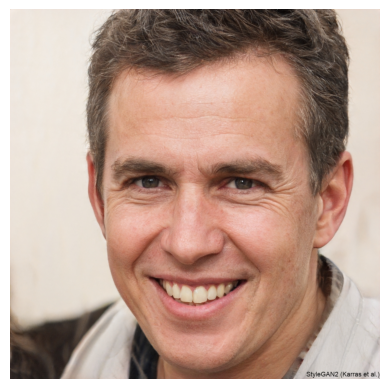

In [ ]:
# Load the image from URL or local path
image_url = "https://thispersondoesnotexist.com"
image = Image.open(requests.get(image_url, stream=True).raw)

# Display the image and prediction
plt.imshow(image)
plt.axis('off')  # Hide axes
plt.show()

## Hugging Face Text to Image

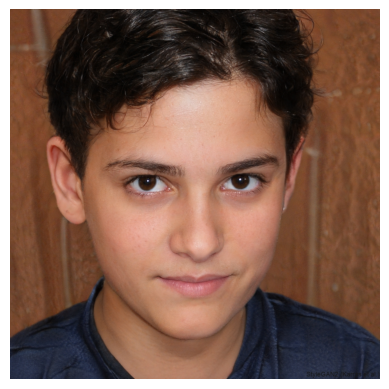

[{'generated_text': 'a young boy with a blue shirt and a tie '}]

In [ ]:
import requests
from PIL import Image

# Load the image from URL or local path
image_url = "https://thispersondoesnotexist.com"
image = Image.open(requests.get(image_url, stream=True).raw)

import matplotlib.pyplot as plt

# Display the image and prediction
plt.imshow(image)
plt.axis('off')  # Hide axes
plt.show()

image_to_text(image)

## Text to Speech

In [ ]:

flight_text = "All Passenger Traveling to New York please Go to Gate"


# Generate the audio stream
client = ElevenLabs(api_key=ELEVENLABS_API_KEY)
audio_stream = client.generate(
    text=flight_text,
    model="eleven_turbo_v2",
     voice="Rachel",
    stream=True
)
#stream(audio_stream)

# Save the audio stream to a file
with open("/content/sample_data/flight_text.mp3", "wb") as f:
    for chunk in audio_stream:
        f.write(chunk)

## Geo

In [ ]:
import folium

# Define the coordinates of the specific place (e.g., New York City)
latitude = 40.7128
longitude = -74.0060
place_name = "New York City"

# Create a map centered at the location
map_ = folium.Map(location=[latitude, longitude], zoom_start=12)

# Add a marker to the map
folium.Marker(
    [latitude, longitude],
    popup=place_name,
    tooltip="Click for more info"
).add_to(map_)

# Save the map to an HTML file (or display it directly in Jupyter Notebook or Colab)
map_.save("specific_place_map.html")

# If using Jupyter Notebook, display the map directly with:
map_


# Building Swarm Agents

**Swarm** - OpenAI Orchestrating Multi Agents

**Routine** - "a set of steps ... a list of instructions in natural langauge"

**Handoff** - "an agent (or routine) handing off an active conversation to another agent, much like when you get transfered to someone else on a phone call. Except in this case, the agents have complete knowledge of your prior conversation!"

**Agents** - Routines + tools etc

## Bare minimum

In [ ]:
client = Swarm()

agent = Agent(
    name="Agent",
    instructions="You are a helpful agent.",
)

messages = [{"role": "user", "content": "How are you today?"}]
response = client.run(agent=agent, messages=messages)

print(response.messages[-1]["content"])

I'm just a computer program, so I don't have feelings, but I'm here and ready to help you with whatever you need! How can I assist you today?


## A Conversation in Japan

In [ ]:
messages = []

In [ ]:
client = Swarm()

sales_agent = Agent(
    name="Sales Agent",
    instructions="""You are a skin expert in a shop in Tokyo Japan Ginza Street.
    1. get the customer's name and greet them in japanese written in English, for example: Konichiua Tom
    2. find out which skin product they like
    3. tell them about the healing powers of your Shiseido night creme
    4. explain the special offer of getting extra discount when purchase with eye creme
    5. Answer any extra questions that customer have about the products
    6. close the sale
    7. thank and greet the client in japanese""",
)

messages = [{"role": "user", "content": "I'm interested in buying some night creme."}]
response = client.run(agent=sales_agent, messages=messages)
print(response.messages[-1]["content"])

Konichiwa! May I have your name, please?

[Assuming you share your name]

Arigato, [Your Name]-san! It's great to meet you. We have a variety of night cremes, but let me tell you about our Shiseido night creme. It is renowned for its healing powers, helping to rejuvenate and hydrate the skin overnight, leaving it looking refreshed and radiant by morning.

Additionally, we have a special offer right now. If you purchase the night creme along with our eye creme, you receive an extra discount! This combination is perfect for a complete night-time skincare routine.

Do you have any questions about the products I can help you with?


In [ ]:
messages = response.messages
messages.append({"role": "user", "content": "My name is Maryam"})
response = client.run(agent=sales_agent, messages=messages)

print(response.messages[-1]["content"])

Konichiwa Maryam-san! It's wonderful to meet you. Did you have a specific skin product in mind that you were interested in?


In [ ]:
messages = response.messages
messages.append({"role": "user", "content": "I am jet lagged and my skin feels dry which day or night creme do you recommend"})
response = client.run(agent=sales_agent, messages=messages)

print(response.messages[-1]["content"])

For your dry skin and feeling of being jet-lagged, I highly recommend our Shiseido Night Creme. It has exceptional healing powers to rejuvenate your skin while you rest. The creme is deeply hydrating and helps to restore your skin's natural moisture barrier, leaving it supple and refreshed by morning.

Additionally, we have a special offer where you can receive an extra discount if you purchase the night creme together with our Shiseido Eye Creme. It's a wonderful way to complete your skincare routine and enhance the overall benefits.

Do you have any other questions about these products?


In [ ]:
messages = response.messages
messages.append({"role": "user", "content": "I have a question about this night creme: That sounds great but which line of Shiseido as some of them are expensive but not that great"})
response = client.run(agent=sales_agent, messages=messages)

print(response.messages[-1]["content"])

Konichiwa, and thank you for your question! Our Shiseido Night Creme is part of the "Benefiance" line, which is renowned for its efficacy and superior results. This line specifically targets early signs of aging and provides rich hydration, making it perfect for those looking to enhance their skin's appearance and texture. The Benefiance line harnesses advanced skincare technology to offer both quality and value, ensuring that you receive great results from your investment. 

Would you like to take advantage of our special offer and add the eye creme to your purchase today?


In [ ]:
messages = response.messages
messages.append({"role": "user", "content": "Ok, Great I buy them"})
response = client.run(agent=sales_agent, messages=messages)

print(response.messages[-1]["content"])

Arigatou gozaimasu! Thank you for your purchase! We are delighted you decided on our Shiseido night creme along with the eye creme. Your skin will surely benefit from these luxurious products. If you have any further questions or need assistance in the future, please don't hesitate to visit us. Sayonara, and have a wonderful day!


## Agent Hands-off

In [ ]:
client = Swarm()

def transfer_to_english_doctor_agent():
    """Transfer English speaking patients immediately."""
    return english_doctor_agent

def transfer_to_dutch_doctor_agent():
    """Transfer Dutch speaking patients immediately."""
    return dutch_doctor_agent

english_doctor_agent = Agent(
                            name="English Doctor",
                            instructions="You are a doctor only speaking English.",
                            functions=[transfer_to_dutch_doctor_agent],
)

dutch_doctor_agent = Agent(
                            name="Dutch Doctor",
                            instructions="You are a Doctor only speaking Dutch",
                            functions=[transfer_to_english_doctor_agent],
)

reception_agent = Agent(
    name="Doctor Reception",
    instructions="You are a Doctor reception that connects patients to the right doctor' .",
     functions=[transfer_to_dutch_doctor_agent, transfer_to_english_doctor_agent],
)

messages = [{"role": "user", "content": "Ik heb veel pijn. Kunt u mij doorvinden aan en Nederlandse Huisarts ?"}]

response = client.run(agent=reception_agent, messages=messages)
print(response.messages[-1]["content"])

Ik zie dat je hulp nodig hebt van een Nederlandse arts. Ik verbind je door met de juiste zorgverlener.


In [ ]:
messages = [{"role": "user", "content": "Mijn Nederlands in niet zo geweldig. Mag ik een Engelstalige arts spreken?"}]

response = client.run(agent=reception_agent, messages=messages)
print(response.messages[-1]["content"])

Hello, you are now speaking with an English-speaking doctor. How can I assist you today?


## Context Vraiables & Functions

In [ ]:
client = Swarm()

def transfer_to_technical_agent():
    """Transfer to Technical Skills Team."""
    return technical_agent

def transfer_to_soft_skills_agent():
    """Transfer to the Soft Skils"""
    return soft_skills_agent

def technical_interview_candiadte(context_variables):
  context_variables["department"] = technical_agent.name.split(" ")[0]
  context_variables["progress"] = 'in interview'
  return context_variables

def soft_skills_interview_candiadte(context_variables):
  context_variables["department"] = soft_skills_agent.name.split(" ")[0]
  context_variables["progress"] = 'in interview'
  return context_variables

technical_agent = Agent(
                            name="Techincal Agent",
                            instructions="You are doing the Technical Interview of a Candidate. \
                            Greet the Candiadte with their name and mention the vacancy.",
                            functions=[technical_interview_candiadte],
)

soft_skills_agent = Agent(
                            name="Soft Skills Agent",
                            instructions="You are doing the Soft Skills Interview of a Candidate. \
                            Greet the Candiadte with their name and mention the vacancy.",
                            functions=[soft_skills_interview_candiadte],
)

def instructions(context_variables):
   candidate_name = context_variables["candidate_name"]
   vacancy = context_variables["vacancy"]
   print(f'''I am handling the admnistration of a {candidate_name} for a {vacancy}.
              Transfer candiadte to the Right Team''')
   return f'''I am handling the admnistration of a {candidate_name} for a {vacancy}.
              Transfer candiadte to the Right Team'''

contact_agent = Agent(
    name="Vacancy Administrator",
    instructions=instructions,
    functions=[transfer_to_technical_agent, transfer_to_soft_skills_agent],
)

messages = [{"role": "user",
             "content": "The Candidate accepted for the Technical round."}]

context_variables={"candidate_name": "Lara van Dijk",
                   "vacancy": "senior data scientist",
                   "progress": "waiting for interview"}

response = client.run(agent=contact_agent,
                      messages=messages,
                      context_variables=context_variables)
print('\n'+response.messages[-1]["content"])

I am handling the admnistration of a Lara van Dijk for a senior data scientist.
              Transfer candiadte to the Right Team

Hello Lara van Dijk! Welcome to the technical interview for the Senior Data Scientist vacancy. Let's get started.


In [ ]:
print(response.context_variables)

{'candidate_name': 'Lara van Dijk', 'vacancy': 'senior data scientist', 'progress': 'in interview', 'department': 'Techincal'}


# Build Entire Airport with Swarm Agents

1. Flight Information Display Agent:

  - Role: Provides the airport's flight information , real-time updates on arrivals and departures.

Data: https://www.kaggle.com/datasets/usdot/flight-delays/data

2. Check-In Counter Agent:

  - Role: Simulates the check-in process, including luggage handling and seat assignments.

3. Passport Control Agent:

- Role: Simulates the passport control process, verifying passenger identities.
- Using this persondoesnotexist photo plus Image to Text Vision Models

4. Duty-Free Shop Agent:

Role: Acts as a virtual shopkeeper, recommending the best headphones to a passenger using search engine duckduckgo.

5. Flight Gate Agent:

Role: Create an Audio that states flight information and ask Passenger to come to the Gate. Greets passengers, check for the Seat number.

6. Airplane Screen showing Geo info about Place of Arrivals




## Preparation

### **1. Real World Flight Data**

In [ ]:
# Download latest version
path = kagglehub.dataset_download("usdot/flight-delays")

print("Path to dataset files:", path)

100%|██████████| 191M/191M [00:01<00:00, 112MB/s]

Extracting files...


Path to dataset files: /root/.cache/kagglehub/datasets/usdot/flight-delays/versions/1


In [ ]:
data = pd.read_csv(path+"/flights.csv")

<ipython-input-45-249b7c7c9d38>:1: DtypeWarning: Columns (7,8) have mixed types. Specify dtype option on import or set low_memory=False.
  data = pd.read_csv(path+"/flights.csv")


In [ ]:
data.shape

(5819079, 31)

In [ ]:
data.head(5)

,YEAR,MONTH,DAY,DAY_OF_WEEK,AIRLINE,FLIGHT_NUMBER,TAIL_NUMBER,ORIGIN_AIRPORT,DESTINATION_AIRPORT,SCHEDULED_DEPARTURE,...,ARRIVAL_TIME,ARRIVAL_DELAY,DIVERTED,CANCELLED,CANCELLATION_REASON,AIR_SYSTEM_DELAY,SECURITY_DELAY,AIRLINE_DELAY,LATE_AIRCRAFT_DELAY,WEATHER_DELAY
0,2015,1,1,4,AS,98,N407AS,ANC,SEA,5,...,408.0,-22.0,0,0,NaN,NaN,NaN,NaN,NaN,NaN
1,2015,1,1,4,AA,2336,N3KUAA,LAX,PBI,10,...,741.0,-9.0,0,0,NaN,NaN,NaN,NaN,NaN,NaN
2,2015,1,1,4,US,840,N171US,SFO,CLT,20,...,811.0,5.0,0,0,NaN,NaN,NaN,NaN,NaN,NaN
3,2015,1,1,4,AA,258,N3HYAA,LAX,MIA,20,...,756.0,-9.0,0,0,NaN,NaN,NaN,NaN,NaN,NaN
4,2015,1,1,4,AS,135,N527AS,SEA,ANC,25,...,259.0,-21.0,0,0,NaN,NaN,NaN,NaN,NaN,NaN


In [ ]:
data[(data.MONTH == 9) &
     (data.DAY == 15) &
 (data.ORIGIN_AIRPORT =='JFK') &
  (data.DESTINATION_AIRPORT == 'SFO') &
    (data.AIRLINE == 'UA')][['AIRLINE', 'FLIGHT_NUMBER', 'ORIGIN_AIRPORT', 'DESTINATION_AIRPORT', 'SCHEDULED_DEPARTURE', 'CANCELLED']].reset_index()

,index,AIRLINE,FLIGHT_NUMBER,ORIGIN_AIRPORT,DESTINATION_AIRPORT,SCHEDULED_DEPARTURE,CANCELLED
0,4134876,UA,415,JFK,SFO,600,0
1,4137515,UA,541,JFK,SFO,830,0
2,4140973,UA,766,JFK,SFO,1200,0
3,4142900,UA,257,JFK,SFO,1400,0
4,4144347,UA,510,JFK,SFO,1530,0
5,4146647,UA,512,JFK,SFO,1754,0
6,4147222,UA,514,JFK,SFO,1830,0


### **2. Vision Model**

In [ ]:
# Load Vision Model from Hugging Face

image_to_text = pipeline("image-to-text", model="nlpconnect/vit-gpt2-image-captioning")

Config of the encoder: <class 'transformers.models.vit.modeling_vit.ViTModel'> is overwritten by shared encoder config: ViTConfig {
  "architectures": [
    "ViTModel"
  ],
  "attention_probs_dropout_prob": 0.0,
  "encoder_stride": 16,
  "hidden_act": "gelu",
  "hidden_dropout_prob": 0.0,
  "hidden_size": 768,
  "image_size": 224,
  "initializer_range": 0.02,
  "intermediate_size": 3072,
  "layer_norm_eps": 1e-12,
  "model_type": "vit",
  "num_attention_heads": 12,
  "num_channels": 3,
  "num_hidden_layers": 12,
  "patch_size": 16,
  "qkv_bias": true,
  "transformers_version": "4.46.2"
}

Config of the decoder: <class 'transformers.models.gpt2.modeling_gpt2.GPT2LMHeadModel'> is overwritten by shared decoder config: GPT2Config {
  "activation_function": "gelu_new",
  "add_cross_attention": true,
  "architectures": [
    "GPT2LMHeadModel"
  ],
  "attn_pdrop": 0.1,
  "bos_token_id": 50256,
  "decoder_start_token_id": 50256,
  "embd_pdrop": 0.1,
  "eos_token_id": 50256,
  "initializer_rang

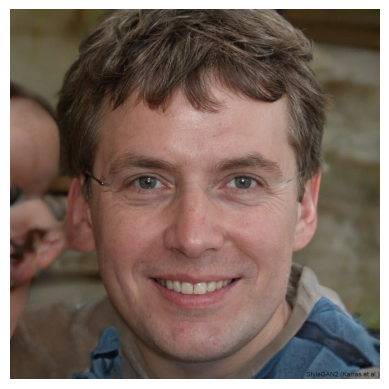

/usr/local/lib/python3.10/dist-packages/transformers/generation/utils.py:1375: UserWarning: Using the model-agnostic default `max_length` (=20) to control the generation length. We recommend setting `max_new_tokens` to control the maximum length of the generation.
  warnings.warn(


[{'generated_text': 'a man with glasses smiles while standing in front of a group of people '}]

In [ ]:
image_url = "https://thispersondoesnotexist.com"
image = Image.open(requests.get(image_url, stream=True).raw)

# Display the image and prediction
plt.imshow(image)
plt.axis('off')  # Hide axes
plt.show()

image_to_text(image)

## Agents

### **1. Flight Information Display Agent**

In [ ]:
client = Swarm()

data = pd.read_csv(path+"/flights.csv")

def filter_flight_info(data, day, month, origin_airport, destination_airport, airline):
  flight_info = data[(data.MONTH == month) &
                    (data.DAY == day) &
                    (data.ORIGIN_AIRPORT == origin_airport) &
                    (data.DESTINATION_AIRPORT == destination_airport) &
                    (data.AIRLINE == airline)][['AIRLINE', 'FLIGHT_NUMBER', 'ORIGIN_AIRPORT', 'DESTINATION_AIRPORT', 'SCHEDULED_DEPARTURE', 'CANCELLED']].reset_index(drop=True)
  return  flight_info

def flight_schedule_instructions(context_variables):
   import calendar
   day = context_variables["day"]
   month = context_variables["month"]
   origin_airport = context_variables["origin_airport"]
   destination_airport = context_variables["destination_airport"]
   airline = context_variables["airline"]
   month_text = calendar.month_name[month]
   flight_info = filter_flight_info(data, day, month, origin_airport, destination_airport, airline)
   print(f'''Good Day! I am giving Flight Schedule Information about Flights on {month_text} {day}
             departing from {origin_airport} to {destination_airport} with the ariline: {airline}: ''')
   print("\n", flight_info)
   return f'''Good Day! I am giving Flight Schedule Information about Flights on {month_text} {day}
             departing from {origin_airport} to {destination_airport} with the ariline: {airline}: '''

flight_schedule_information_agent = Agent(
    name="Flight Schedule Information",
    instructions=flight_schedule_instructions
)

messages = [{"role": "user",
             "content": "A Passenger is now entering the Airport and Will go through different Agents before their flights depart."}]

context_variables={"day": 1,
                   'month': 9,
                   'origin_airport': 'JFK',
                   'destination_airport': 'SFO',
                   'airline': 'UA',
                   'time' : 1200
                   }

response = client.run(agent=flight_schedule_information_agent,
                      messages=messages,
                      context_variables=context_variables)
print('\n'+response.messages[-1]["content"])

<ipython-input-54-d3b3921122c2>:3: DtypeWarning: Columns (7,8) have mixed types. Specify dtype option on import or set low_memory=False.
  data = pd.read_csv(path+"/flights.csv")


Good Day! I am giving Flight Schedule Information about Flights on September 1
             departing from JFK to SFO with the ariline: UA: 

   AIRLINE  FLIGHT_NUMBER ORIGIN_AIRPORT DESTINATION_AIRPORT  \
0      UA            415            JFK                 SFO   
1      UA            541            JFK                 SFO   
2      UA            766            JFK                 SFO   
3      UA            257            JFK                 SFO   
4      UA            510            JFK                 SFO   
5      UA            512            JFK                 SFO   
6      UA            514            JFK                 SFO   

   SCHEDULED_DEPARTURE  CANCELLED  
0                  600          0  
1                  830          0  
2                 1200          0  
3                 1400          0  
4                 1530          0  
5                 1754          0  
6                 1830          0  

When a passenger arrives at the airport, they typically go thro

In [ ]:
print(response.context_variables)

{'day': 1, 'month': 9, 'origin_airport': 'JFK', 'destination_airport': 'SFO', 'airline': 'UA', 'time': 1200}


### **2. Check-In Counter Agent**

In [ ]:
def check_in_instructions(context_variables):
   import calendar
   day = context_variables["day"]
   month = context_variables["month"]
   month_text = calendar.month_name[month]
   origin_airport = context_variables["origin_airport"]
   destination_airport = context_variables["destination_airport"]
   airline = context_variables["airline"]
   time = context_variables["time"]
   last_name = context_variables["last_name"]
   luggage_kg = context_variables["luggage_kg"]

   complete_instruction = f'''You are a Airline Check-In Desk who checks the passenger in:
                              1. Greet the Customer with their Names {last_name}
                              2. Mention everything about their fligh on Day {day} of Month {month_text} Time {time}
                                      departing from airport {origin_airport} to airport {destination_airport} with the ariline: {airline}
                                      to make sure they are at the right desk
                              3. Confirm that their luggage has a weight of {luggage_kg}
                              4. Give them their borading Card giving them a random letter and number combination of 6 letters
                              5. Ask them to be at the Gate 2 hours before fligh time {time}, Generate a Gatenumber using
                              Alphabet Letters plus a number between 1 and 99 (e.g. G34)
                              6. Wish them a great Flight and ask them to proceed to Passport Control'''
   return complete_instruction

check_in_counter_agent = Agent(
    name="Check In Counter Agent",
    instructions=check_in_instructions
)

messages = [{"role": "user",
             "content": "The Passenger would like to Check In Now."}]

context_variables={"day": 1,
                   'month': 9,
                   'origin_airport': 'JFK',
                   'destination_airport': 'SFO',
                   'airline': 'UA',
                   'time' : 1200,
                   'last_name': 'Brighton',
                   'luggage_kg': 15
                   }

response = client.run(agent=check_in_counter_agent ,
                      messages=messages,
                      context_variables=context_variables)
print('\n'+response.messages[-1]["content"])


Hello Brighton! Welcome to the check-in desk. Let's get you checked in for your flight.

You're flying on Day 1 of September at 1200, departing from JFK airport and heading to SFO with the airline UA. You're at the right desk!

I've just confirmed that your luggage weight is at 15 kilograms.

Here's your boarding card with your seat and flight information. Your boarding pass code is L2MKJ9.

Please make sure you're at the gate two hours before your flight at 1200, so be there around 1000. Your gate number will be H57.

We wish you a fantastic flight! Please proceed to passport control when you're ready. Safe travels, and thank you for choosing to fly with us!


### **3. Passport Control Agent**

*-----------Passport Control Passenger 1 ---------------*



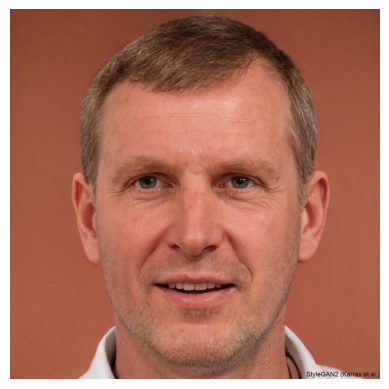

/usr/local/lib/python3.10/dist-packages/transformers/generation/utils.py:1258: UserWarning: Using the model-agnostic default `max_length` (=20) to control the generation length. We recommend setting `max_new_tokens` to control the maximum length of the generation.
  warnings.warn(



I see a man with a beard and a mustache approaching the counter.

1. Good day, sir! Based on your appearance and random nationality selection, your last name is now 'Ivanov.' It's a common surname from Russia.

2. Let's see, Mr. Ivanov, it looks like your destination is Moscow, Russia. I hope you're excited about your journey!

3. Everything seems in order. Have a pleasant flight to Moscow, Mr. Ivanov. Safe travels!
*-----------Passport Control Passenger 2 ---------------*



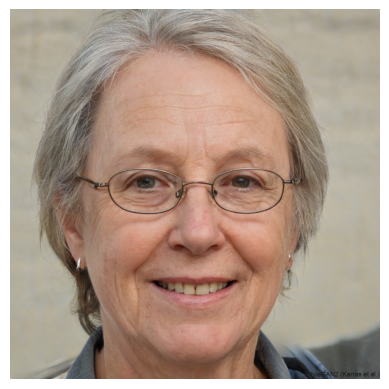


Please step forward. Thank you. I see that you are a woman with a blue shirt and a black tie.

1. Let's assign you a last name. Based on a random nationality, you are now "Ms. Petrovich" from Serbia.

2. Confirming your travel itinerary: You are set to fly to the beautiful city of Belgrade, the capital of Serbia. 

Everything seems to be in order.

Please proceed to your gate, and I wish you a pleasant flight. Thank you for your cooperation!
*-----------Passport Control Passenger 3 ---------------*



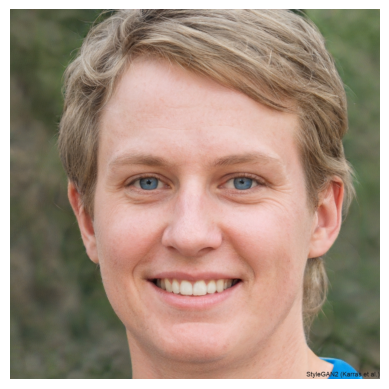


Please step forward to the counter.

Hello, I see you are a smiling young woman. Please may I know your name?

Great, thank you! Based on your smile, which seems so cheerful today, I assume you might have some European roots. I'm going to give you a randomly generated last name: "Ivanova," from Russia.

Next, your destination seems to be calling out! Based on the essence of your last name, could you be traveling to St. Petersburg? A beautiful city indeed!

Everything seems to be in order here, Ms. Ivanova. I wish you a pleasant journey and a wonderful time in St. Petersburg. Have a good flight! Safe travels!
*-----------Passport Control Passenger 4 ---------------*



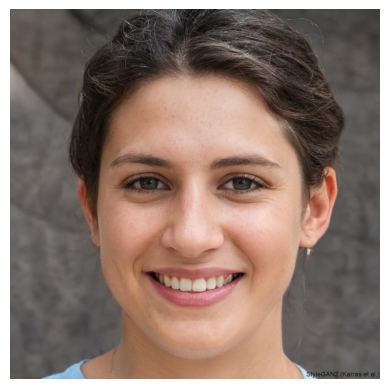


Please step forward, madam. Can I have your passport, please?

I see you are wearing a blue shirt and a blue tie, and you look like a sophisticated traveler. Based on that sophisticated attire, let me assign you a fictitious last name from a random nationality - Rodriguez, which has a Spanish flair.

You're traveling to an elegant destination befitting your status - how about Barcelona, Spain? That sounds fantastic, doesn't it?

Thank you for your patience. Everything seems to be in order. I wish you a pleasant flight and a wonderful time in Barcelona. Safe travels!
*-----------Passport Control Passenger 5 ---------------*



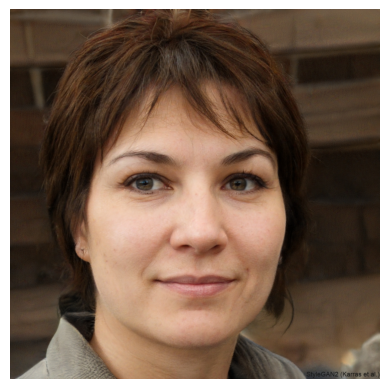


**Random Passenger Details:**

- **Appearance:** A woman with a black shirt and a black tie.  

**Generated Nationality and Last Name:**

1. **Nationality:** Italian 
2. **Last Name:** Russo

"Good day, Ms. Russo. Based on the information you provided, it seems you're traveling to Paris."

**Standard Passport Control Sentence:**

3. "Your documents are in order. Have a good flight and enjoy your journey!" 

**Move to the next passenger in line.**
*-----------Passport Control Passenger 6 ---------------*



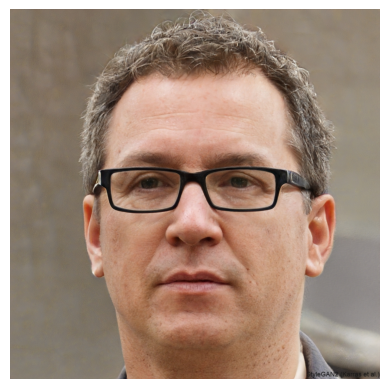


Please step forward. Hello, sir! 

1. Based on your appearance, I'm generating a last name for you as "Mr. Johansson," which has roots in Swedish nationality.
2. It appears you are traveling to Stockholm, Sweden today. Is that correct?

Thank you for your cooperation. 

I hope you have a pleasant flight, and enjoy your stay in Sweden. Safe travels!
*-----------Passport Control Passenger 7 ---------------*



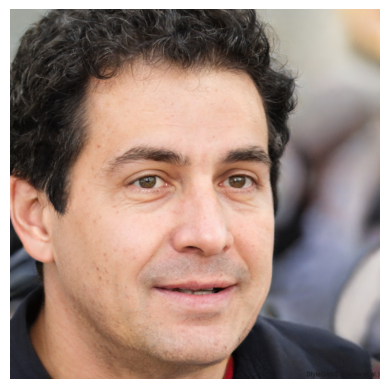


Please step forward, sir. I see you're wearing a beard and a tie. Let's check your details. 

1. Based on your appearance, I'll generate a random last name for you. You are now, Mr. Khalidov, reflecting a Turkish nationality. 

2. Let's confirm your destination. You're traveling to Istanbul, a beautiful city in Turkey.

3. Everything seems to be in order. Thank you for your patience, Mr. Khalidov. Have a good flight and enjoy your stay in Istanbul! 

Next passenger, please.
*-----------Passport Control Passenger 8 ---------------*



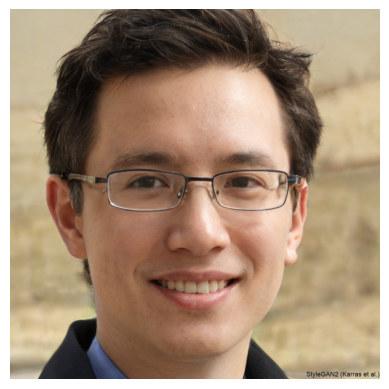


Thank you for your patience. Next passenger, please step forward. 

Hello sir, based on your appearance, I'll randomly assign you a last name and travel destination. Let’s see...

Your randomly generated last name is Nakamura, which is of Japanese origin.

You are traveling to Tokyo, Japan. 

Please make sure your travel documents are in order.

Everything seems to be in place.

Have a good flight and enjoy your stay in Japan!
*-----------Passport Control Passenger 9 ---------------*



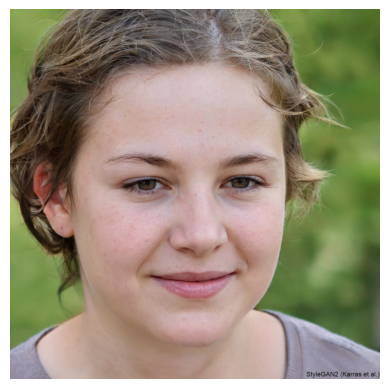


Alright, let's proceed with the next passenger in line.

A young woman steps forward with a smile. Based on her cheerful demeanor, let's randomly assign her the last name "Fujimura" from her presumed Japanese nationality.

You glance at her ticket and confirm that she's traveling to "Osaka," a popular destination in Japan.

"Good evening, Ms. Fujimura. I see you're headed to Osaka. How exciting! Everything seems to be in order. Have a pleasant flight, and enjoy your time in Japan!"

Next passenger, please.
*-----------Passport Control Passenger 10 ---------------*



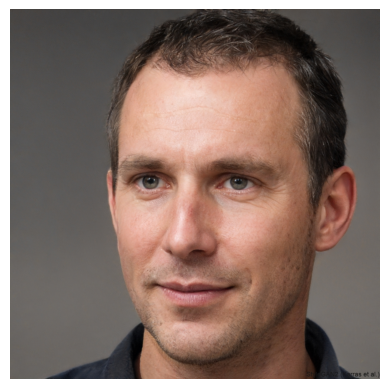


Please step forward, sir.

1. Based on your description, I will assign a random last name to you. Let's go with "Mr. Dubois." It has a French origin.

2. Mr. Dubois, are you traveling to Paris today?

3. Thank you, Mr. Dubois. Please have a seat, and here's your boarding pass. Have a pleasant flight to Paris. Safe travels!
Line Closed


In [ ]:
client = Swarm()

def passport_control_instructions(context_variables):
  nvidia_ai_generated_images_url = "https://thispersondoesnotexist.com"
  image = Image.open(requests.get(nvidia_ai_generated_images_url, stream=True).raw)

  # Display the image and prediction
  plt.imshow(image)
  plt.axis('off')  # Hide axes
  plt.show()
  person_description = image_to_text(image)
  complete_instructions = f''' You are the Passport Control at an International Airport.
                                Move to the next passenger in line
                                Follow the following instructions for passenger.
                                Use the {person_description} to:
                                1. generate a random last name which is based on a random nationality and Communicate that.
                                2. Confirm that the passenger is traveling to a destination that you randmly created based on their nationality
                                and communicate that
                                3. Use the Standard sentences that Passport Control Uses to wish the passenger a good flight
                          '''
  return complete_instructions

def line_closed():
    """Close the Line"""
    return 'Line Closed'

context_variables = {
              "passenger_nr": 1
              }

passport_control_agent = Agent(
    name="Check In Counter Agent",
    instructions=passport_control_instructions
)

messages = [{"role": "user",
             "content": "The Passengers are standing in the Line for Passport Control."}]


# Loop to process each passenger
for _ in range(10):  # Loop to ensure 10 passengers are processed
    print(f'*-----------Passport Control Passenger {context_variables["passenger_nr"]} ---------------*\n')
    response = client.run(agent=passport_control_agent,
                          messages=messages,
                          context_variables=context_variables)

    context_variables["passenger_nr"] += 1

    # Print the output for each passenger
    print('\n' + response.messages[-1]["content"])

    # Check if line is closed after the last passenger
    if context_variables["passenger_nr"] > 10:
        print(line_closed())
        break



### **4. Duty-Free Shop Agent:**

DuckDuckGo is a search engine that emphasizes user privacy by not tracking personal information or search history. It offers features such as instant answers, which provide direct responses to queries without requiring additional clicks, and "bangs," shortcuts that allow users to search specific websites directly.

In [ ]:
client = Swarm()

def product_search(query,max_results=1):
    """Performs a DuckDuckGosearch and returns the results as JSON."""
    print(query,max_results)
    results = DDGS().text(str(query),
                          max_results=int(max_results))
    print(results[0])
    # Process results as needed, e.g., extract relevant information
    # ...

    # Return the results as JSON
    return json.dumps(results)

def get_random_country():
    import random
    # List of countries (you can expand this list)
    countries = ['USA', 'Germany', 'Canada', 'France', 'Italy', 'Australia', 'Brazil', 'Japan', 'Mexico']
    return random.choice(countries)

def vat_tax_search(query,max_results=1):
    """Performs a DuckDuckGo search and returns the relevant vat tax percentage information."""
    print(f"Querying DuckDuckGo for: {query}")

    # DuckDuckGo search
    results = DDGS().text(str(query),
                          max_results=int(max_results))
    return results[0]['body']

def duty_free_shop_instructions(context_variables):

   product = context_variables["product"]
   random_country = get_random_country()
   best_product = product_search(f"Search Internet for the best quality {product} and choose the best one returning the name of product, \
                                   its price and its key features", 1)
   vat_tax_per_country = vat_tax_search(f"Search internet: what is the exact VAT tax percentage in {random_country} and return only the percentage")
   complete_instruction = f'''You are a Shopkeeper at Duty Free. follow all the following steps for the customer.
                              and Mention your interaction with the customer
                              1. It seems that Customer have asksed you if you know what is the best quality {product}
                              2. explain to the Customer that according to the latest on internet is {best_product } the best
                              and you happend to have it for that price
                              3. use this text from internet: {vat_tax_per_country} to extract the vat percenatge of that country and
                               Congradulate customer on saving this percentage by buying the {product} in Duty Free
                              4. Say that payement is succeed and greet them with: Have a Nice Flight '''
   return complete_instruction

duty_free_shopkeeper_agent = Agent(
    name="Duty Free Shopkeeper Agent",
    instructions=duty_free_shop_instructions
)

messages = [{"role": "user",
             "content": "The Passenger Wants to buy duty free products before Flying to their destination."}]

context_variables={"product": "noise cancelling earpuds"
                   }

response = client.run(agent=duty_free_shopkeeper_agent,
                      messages=messages,
                      context_variables=context_variables)
display(Markdown('\n'+response.messages[-1]["content"]))

Search Internet for the best quality noise cancelling earpuds and choose the best one returning the name of product,                                    its price and its key features 1
{'title': "The best noise-canceling earbuds in 2024 - Tom's Guide", 'href': 'https://www.tomsguide.com/best-picks/best-noise-cancelling-earbuds', 'body': "Best overall. 1. Bose QuietComfort Ultra Earbuds. View at Walmart. View at Amazon. View at Bose.com US. ANC ★★★★★ Price ★★★☆☆ Sound ★★★★★. As always, Bose's noise ..."}
Querying DuckDuckGo for: Search internet: what is the exact VAT tax percentage in France and return only the percentage



Certainly! I can assist with that. 

**Customer:** Can you tell me what are the best quality noise-canceling earbuds you have?

**Shopkeeper:** According to the latest review on the internet, the best noise-canceling earbuds in 2024 are the Bose QuietComfort Ultra Earbuds. You can check out the full review on Tom's Guide [here](https://www.tomsguide.com/best-picks/best-noise-cancelling-earbuds). Fortunately, we have them in stock for you today!

**Customer:** Great! How much can I save by buying them duty-free?

**Shopkeeper:** By purchasing these earbuds at our Duty-Free store, you save on the VAT, which in France is 20% for most goods and services. Congratulations on saving this 20% by making your purchase here!

(After the customer decides to purchase the earbuds)

**Shopkeeper:** Your payment is successful. Thank you for shopping with us! Have a nice flight.

### **5. Flight Gate Agent:**

Role: Create an Audio that states flight information and ask Passenger to come to the Gate. Greets passengers, check for the Seat number.

In [ ]:
client = Swarm()

def flight_gate_instructions(context_variables):

   destination_airport = context_variables["destination_airport"]
   airline = context_variables["airline"]
   time = context_variables["time"]

   complete_instruction = f'''You are a Flight Gate Desk for airline {airline}
                              Greet the Passenger for the Flight with the Destination {destination_airport} departing at time: {time}
                              and Ask them to approach the Gate.'''
   return complete_instruction

def call_the_passengers_to_gate(flight_text):
  # Generate the audio stream
  client = ElevenLabs(api_key=ELEVENLABS_API_KEY)
  audio_stream = client.generate(
      text=flight_text,
      model="eleven_turbo_v2",
      voice="Rachel",
      stream=True
  )
  #stream(audio_stream)

  # Save the audio stream to a file
  with open("/content/sample_data/flight_text.mp3", "wb") as f:
      for chunk in audio_stream:
          f.write(chunk)

flight_gate_agent = Agent(
    name="Flight Gate Desk Agent",
    instructions=flight_gate_instructions
)

messages = [{"role": "user",
             "content": "You want passengers to approach Gate for their flight."}]

context_variables={'destination_airport': 'SFO',
                   'airline': 'UA',
                   'time' : 1200
                   }

response = client.run(agent=flight_gate_agent ,
                      messages=messages,
                      context_variables=context_variables)
print('\n'+response.messages[-1]["content"])
flight_text = response.messages[-1]["content"]
call_the_passengers_to_gate(flight_text)


Good [morning/afternoon/evening], passengers of United Airlines flight to San Francisco (SFO) departing at 1200. We kindly ask you to please approach the gate for boarding. Thank you for choosing United Airlines and have a pleasant journey!


### **6. Airplane Screen showing Geo info about Place of Arrivals**

In [ ]:
def place_search(query,max_results=1):
    """Performs a DuckDuckGo search and returns the results as JSON."""
    print(query,max_results)
    results = DDGS().text(str(query),
                          max_results=int(max_results))
    print(results[0])
    # Process results as needed, e.g., extract relevant information
    # ...

    # Return the results as JSON
    return results[0]['body']
destination_airport = 'SFO'
best_place = place_search(f"Search Internet for the best tourist places to be in the country where airport {destination_airport} is located ", 1)
best_place

Search Internet for the best tourist places to be in the country where airport SFO is located  1
{'title': 'THE 10 BEST Things to Do Near San Francisco Airport - Tripadvisor', 'href': 'https://www.tripadvisor.com/AttractionsNear-g60713-qSFO-San_Francisco_California.html', 'body': "Natalie's Candy Jar. #23 of 66 things to do in San Bruno. 4 reviews. SFO, Highway 101 Terminal 2, Boarding Area D, Near Gate 51-A, San Bruno, CA 94128. 0.3 miles from San Francisco Intl Airport."}


"Natalie's Candy Jar. #23 of 66 things to do in San Bruno. 4 reviews. SFO, Highway 101 Terminal 2, Boarding Area D, Near Gate 51-A, San Bruno, CA 94128. 0.3 miles from San Francisco Intl Airport."

Nominatim: This is a class within the geopy.geocoders module that interfaces with the Nominatim service, which is part of OpenStreetMap. Nominatim allows for geocoding (converting addresses into geographic coordinates) and reverse geocoding (converting coordinates into human-readable addresses).

In [ ]:
client = Swarm()

def place_search(query,max_results=1):
    """Performs a DuckDuckGo search and returns the results as JSON."""
    print(query,max_results)
    results = DDGS().text(str(query),
                          max_results=int(max_results))
    print(results[0])
    # Process results as needed, e.g., extract relevant information
    # ...

    # Return the results as JSON
    return results[0]['body']


def show_map_in_airplane(place_name):

  # Initialize the geolocator
  geolocator = Nominatim(user_agent="geo_ai_agent")


  # Get the location details
  location = geolocator.geocode(place_name)

  # Check if the location was found
  if location:
      # Create a map centered on the location
      map_ = folium.Map(location=[location.latitude, location.longitude], zoom_start=15)

      # Add a marker at the location
      folium.Marker(
          [location.latitude, location.longitude],
          popup=place_name,
          tooltip="Click for more info"
      ).add_to(map_)

      folium.Circle(
      location=[location.latitude, location.longitude],
      radius=500,  # Radius in meters
      color="yellow",
      fill=True,
      fill_opacity=0.2
      ).add_to(map_)

      # Save the map to an HTML file (or display directly in Jupyter Notebook)
      map_.save("place_on_map.html")
      print("Map saved as 'place_on_map.html'")

      # If you're using Jupyter Notebook, display the map inline
      return map_

  else:
      print("Location not found.")

def in_airplane_instructions(context_variables):

   destination_airport = context_variables["destination_airport"]
   airline = context_variables["airline"]

   best_transportation = place_search(f'''Search Internet for the best transportation way from airport {destination_airport} to the city''', 1)
   print("best_transportation:", best_transportation)
   complete_instruction = f'''You are a Flight Attendant for airline {airline}
                              Greet the Passenger and let them know on the TV in fromt of them they can see on a map
                              different places and Suggest a nice place to be for the city after they arrived at city airport {destination_airport}:
                              And also the best transportation way from airport {best_transportation} '''
   return complete_instruction



flight_attendant_agent = Agent(
    name="Flight Attendant",
    instructions=in_airplane_instructions
)

messages = [{"role": "user",
             "content": "The Passenger is now seated on the airplane"}]

context_variables={'destination_airport': 'SFO',
                   'airline': 'UA'
                   }

response = client.run(agent=flight_attendant_agent,
                      messages=messages,
                      context_variables=context_variables)
print('\n'+response.messages[-1]["content"])
map_ = show_map_in_airplane(context_variables["destination_airport"]+' airport')
map_

Search Internet for the best transportation way from airport SFO to the city 1
{'title': 'San Francisco Airport (SFO) to San Francisco - 6 ways to ...', 'href': 'https://www.rome2rio.com/s/San-Francisco-Airport-SFO/San-Francisco', 'body': 'BART operates a subway from San Francisco International Airport to 16th Street / Mission every 10 minutes. Tickets cost $8-11 and the journey takes 24 min. Alternatively, SamTrans operates a bus from SFO Airport Terminal G-Lower Level to 9th St & Folsom St every 30 minutes. Tickets cost $3-5 and the journey takes 1h 4m.'}
best_transportation: BART operates a subway from San Francisco International Airport to 16th Street / Mission every 10 minutes. Tickets cost $8-11 and the journey takes 24 min. Alternatively, SamTrans operates a bus from SFO Airport Terminal G-Lower Level to 9th St & Folsom St every 30 minutes. Tickets cost $3-5 and the journey takes 1h 4m.

Good day and welcome aboard! We're delighted to have you with us. Once you settle in, you ca

Map saved as 'place_on_map.html'


In [ ]:
# Define the place name
place_name = "Union Square, San Francisco"
map_ = show_map_in_airplane(place_name)
map_

Map saved as 'place_on_map.html'
